In [1]:
import pandas as pd 
import numpy as np 

df = pd.read_csv("/home/amor/Projects/ETA/data/csv/Projects/online+shoppers+purchasing+intention+dataset/online_shoppers_intention.csv") 

df_copy = df.copy()

## Phase 1 : Basic EDA

In [2]:
df_copy.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
print(f"duplicates: {df_copy.duplicated().sum()}\nMissings:\n{df_copy.isnull().sum()}\n")

duplicates: 125
Missings:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64



In [4]:
df_copy = df_copy.rename(columns = {"Revenue":"target"})
df_copy["target"] = df_copy["target"].astype(int)

X = df_copy.drop(columns = ["target"])
y = df_copy["target"]

In [5]:
num_cols = ["SpecialDay","PageValues","ExitRates","BounceRates","ProductRelated_Duration","ProductRelated","Informational_Duration","Informational","Administrative_Duration","Administrative"] 

cat_cols = ["Weekend" , "Month" , "OperatingSystems","Browser" , "Region" , "TrafficType" , "VisitorType"]

In [6]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [7]:
df_copy.shape

(12330, 18)

## Phase 2 (Advanced EDA) : Target Analysis

target
0    10422
1     1908
Name: count, dtype: int64
target
0    0.845255
1    0.154745
Name: proportion, dtype: float64


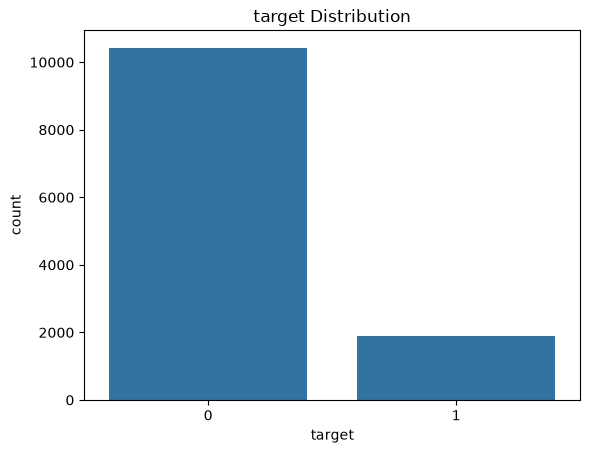

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

print(df_copy["target"].value_counts())
print(df_copy["target"].value_counts(normalize=True))

sns.countplot(data=df_copy, x="target")
plt.title("target Distribution")
plt.show()

## Phase 3: Advanced EDA: Num Features

In [9]:
df_copy[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000


In [10]:
df_copy[num_cols].skew().sort_values(ascending=False)

Informational_Duration     7.579185
ProductRelated_Duration    7.263228
PageValues                 6.382964
Administrative_Duration    5.615719
ProductRelated             4.341516
Informational              4.036464
SpecialDay                 3.302667
BounceRates                2.947855
ExitRates                  2.148789
Administrative             1.960357
dtype: float64

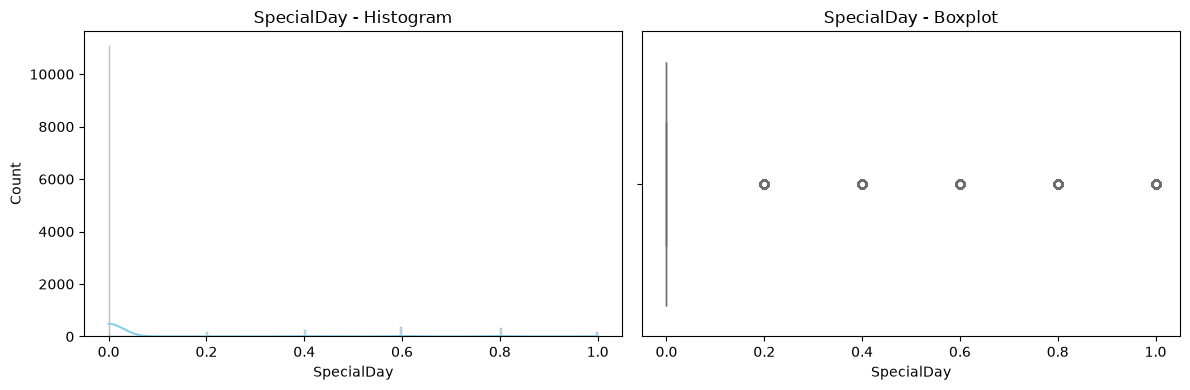

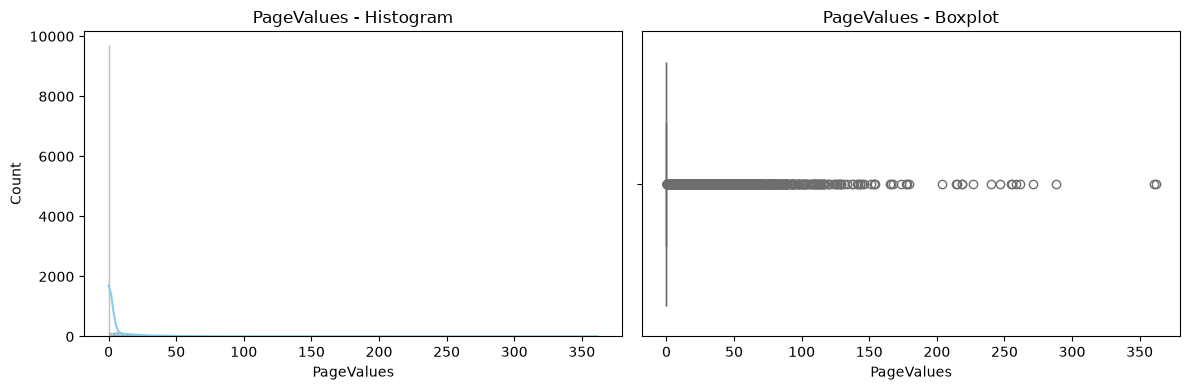

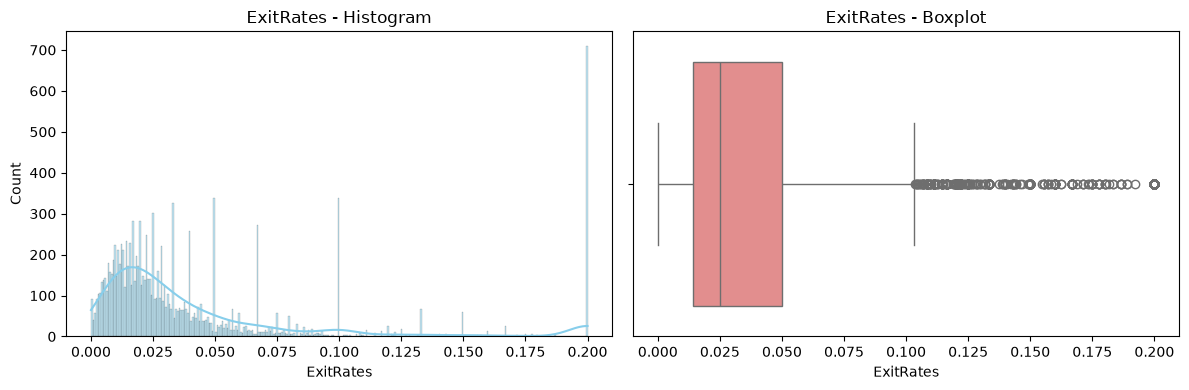

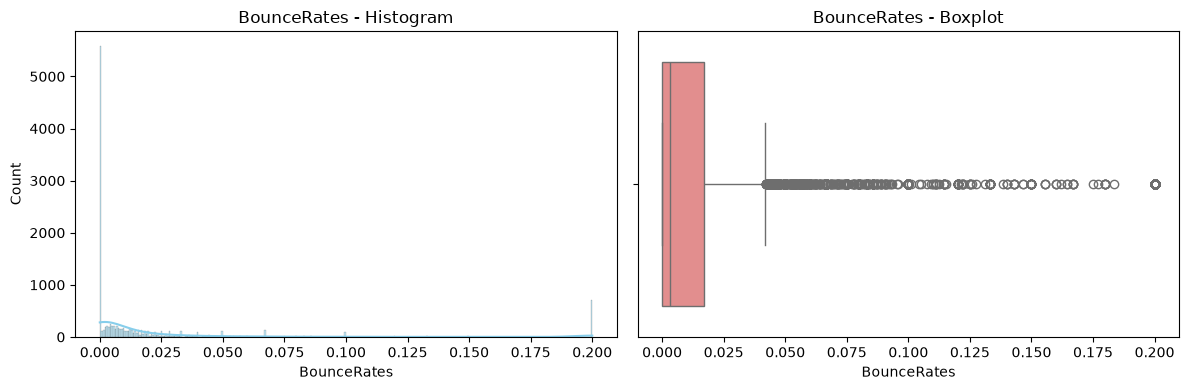

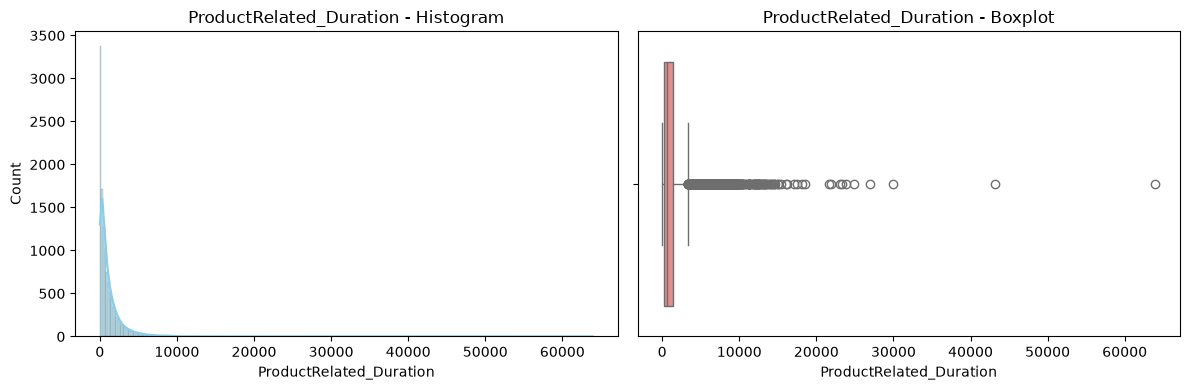

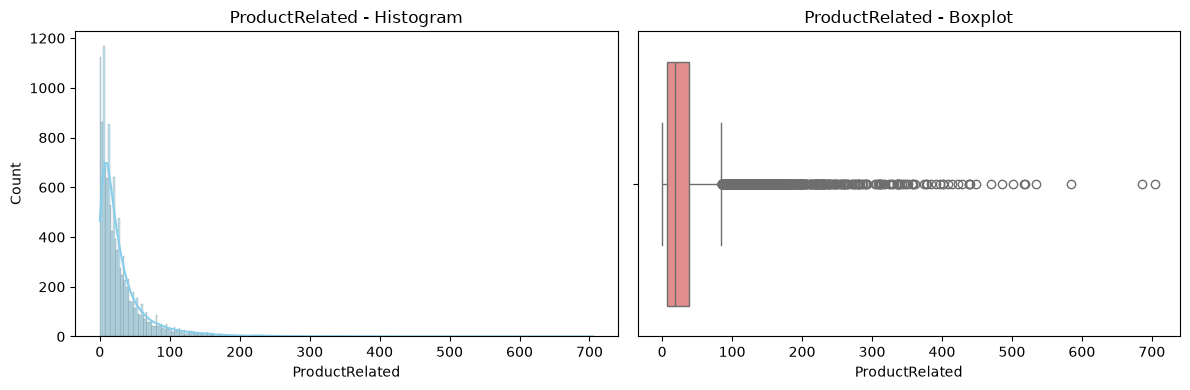

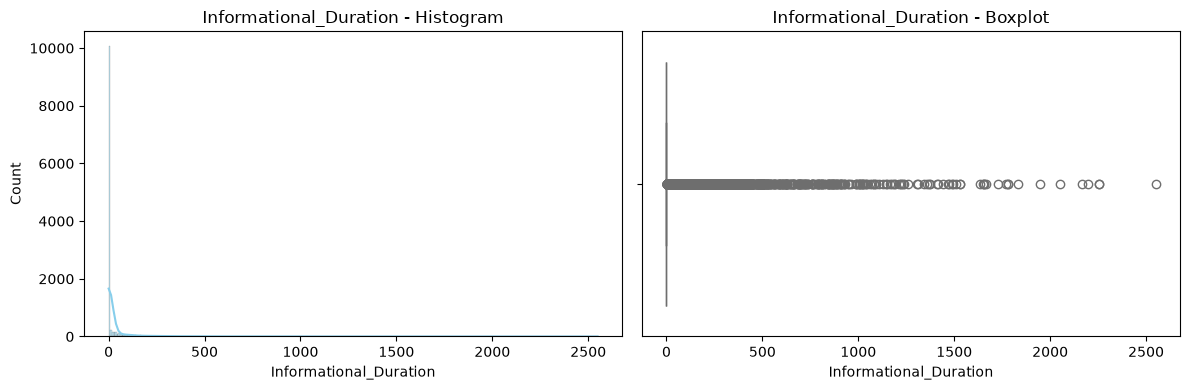

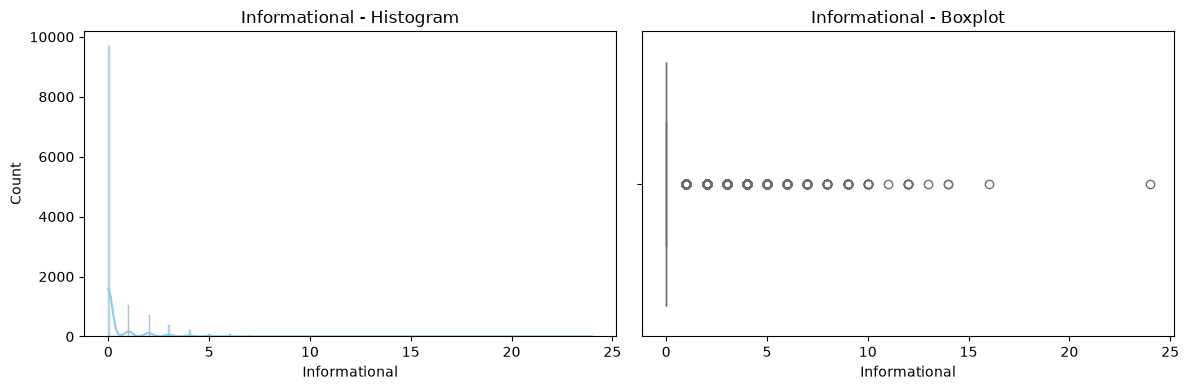

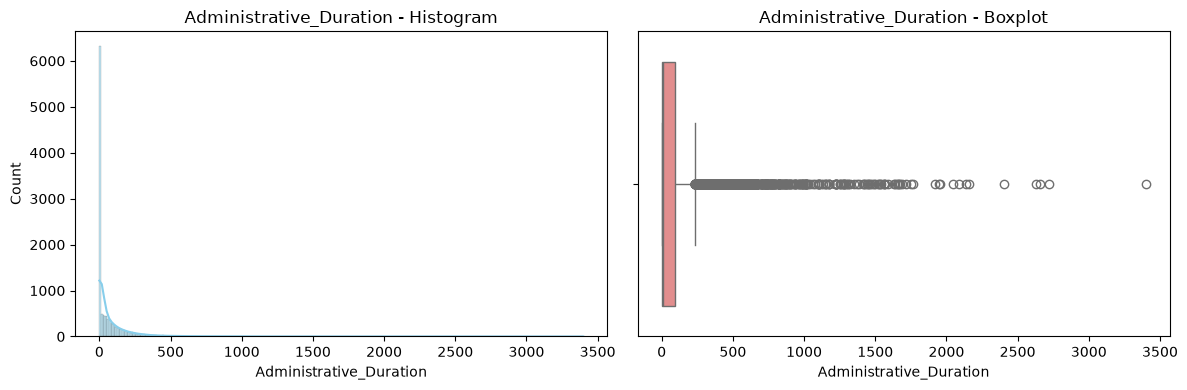

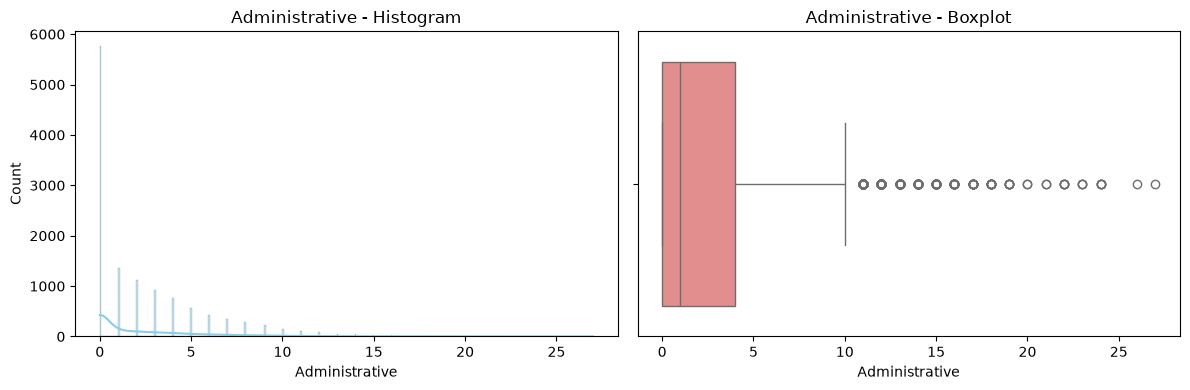

In [11]:
# Create a figure with 2 subplots side-by-side (1 row, 2 columns)
for cols in num_cols:
    fig , axes = plt.subplots(1, 2, figsize=(12, 4))

    # Left subpnom_vals =lot: Histogram with a Density Curve (KDE)

    sns.histplot(data=df[num_cols], x=cols, kde=True, ax=axes[0], bins= 300, color="skyblue")
    axes[0].set_title(cols + " - Histogram")

    # Right subplot: Boxplot
 
    sns.boxplot(data=df[num_cols], x=cols, ax=axes[1], color="lightcoral")
    axes[1].set_title(cols + " - Boxplot")

    # Clean up layout and render the plots for this feature
    plt.tight_layout()
    plt.show()

In [12]:
zero_ratio = (df_copy[num_cols] == 0).mean()

print(
    zero_ratio
    .sort_values(ascending=False)
)

SpecialDay                 0.898540
Informational_Duration     0.804947
Informational              0.786618
PageValues                 0.778589
Administrative_Duration    0.478751
Administrative             0.467802
BounceRates                0.447526
ProductRelated_Duration    0.061233
ExitRates                  0.006164
ProductRelated             0.003082
dtype: float64


### (B): target with Num Features

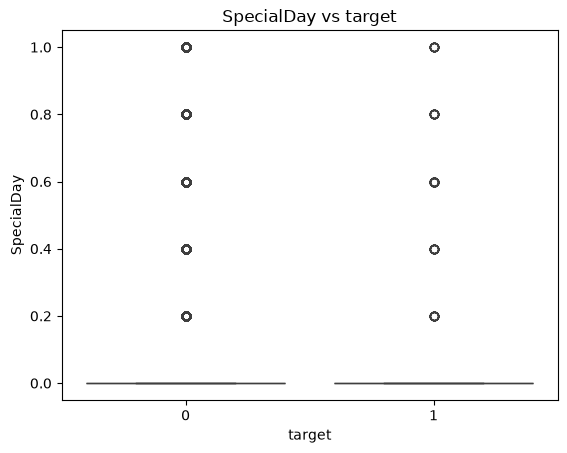

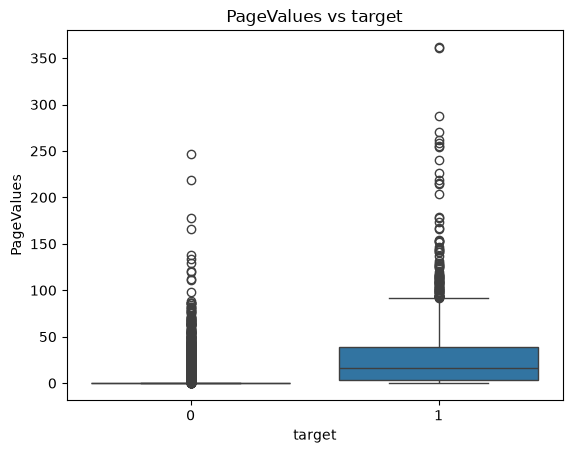

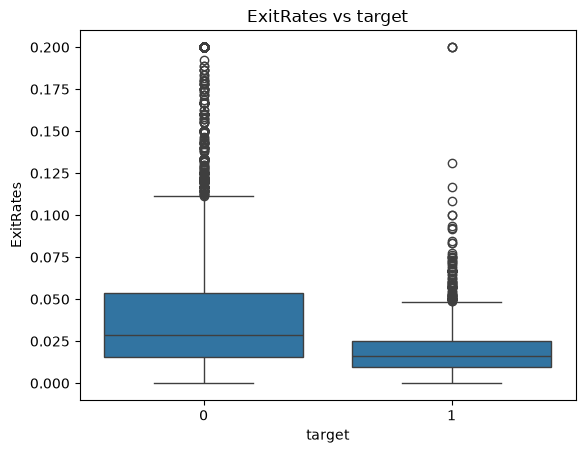

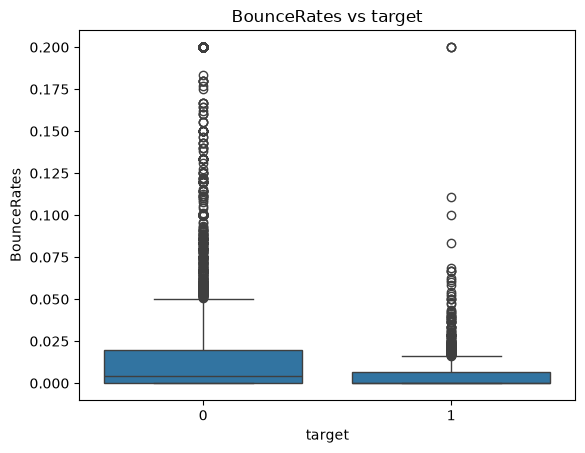

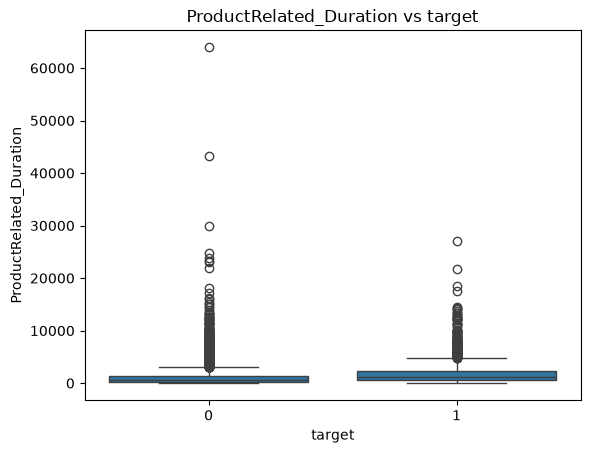

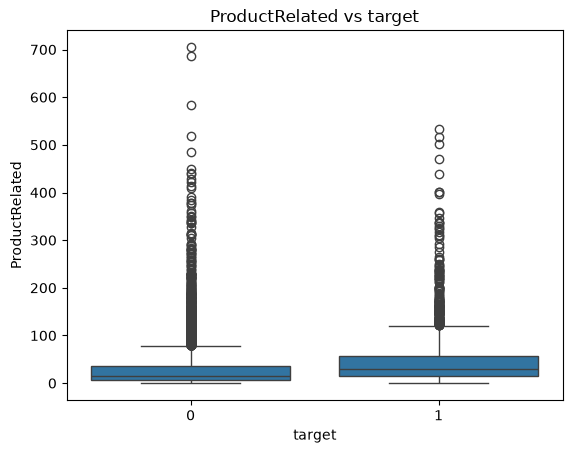

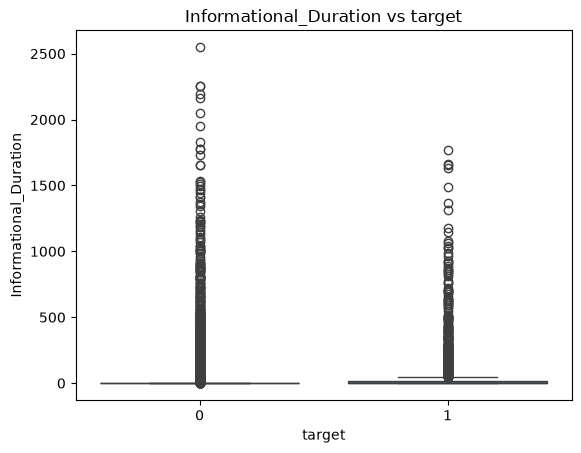

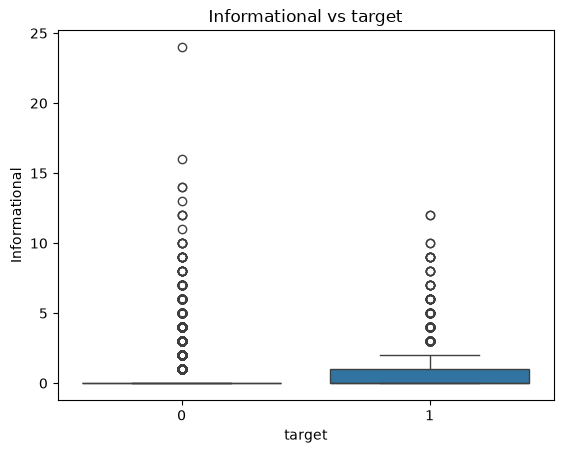

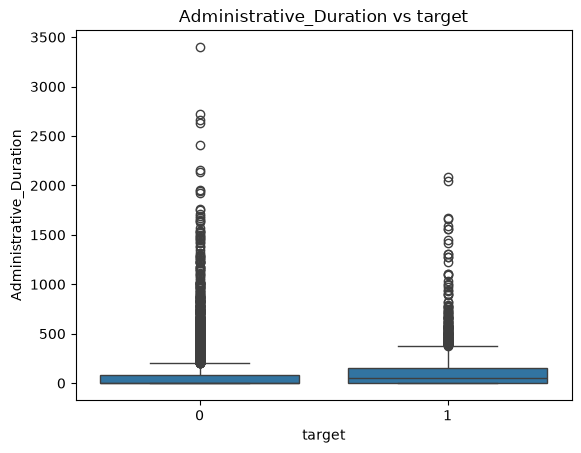

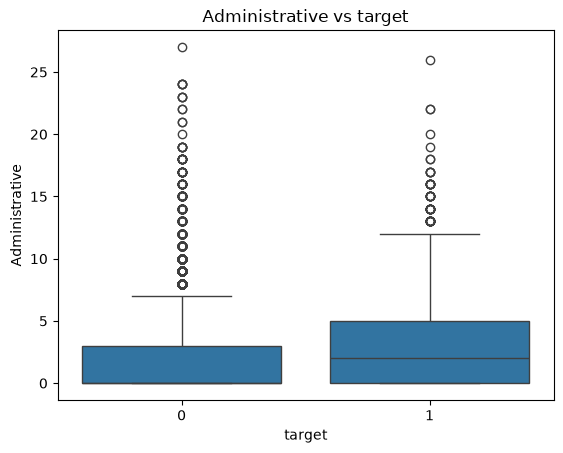

In [13]:
for col in num_cols:

    sns.boxplot(
        data=df_copy,
        x="target",
        y= col
    )

    plt.title(f"{col} vs target")
    plt.show()

In [14]:
df_copy.groupby("target")[num_cols].mean()

,SpecialDay,PageValues,ExitRates,BounceRates,ProductRelated_Duration,ProductRelated,Informational_Duration,Informational,Administrative_Duration,Administrative
target,,,,,,,,,,
0,0.068432,1.975998,0.047378,0.025317,1069.987809,28.714642,30.236237,0.451833,73.740111,2.117732
1,0.023166,27.264518,0.019555,0.005117,1876.209615,48.210168,57.611427,0.786164,119.483244,3.393606


In [15]:
corr = df_copy.select_dtypes(include=np.number).corr()

print(
    corr["target"]
    .sort_values(ascending=False)
)

target                     1.000000
PageValues                 0.492569
ProductRelated             0.158538
ProductRelated_Duration    0.152373
Administrative             0.138917
Informational              0.095200
Administrative_Duration    0.093587
Informational_Duration     0.070345
Browser                    0.023984
TrafficType               -0.005113
Region                    -0.011595
OperatingSystems          -0.014668
SpecialDay                -0.082305
BounceRates               -0.150673
ExitRates                 -0.207071
Name: target, dtype: float64


### (C): Features with Features

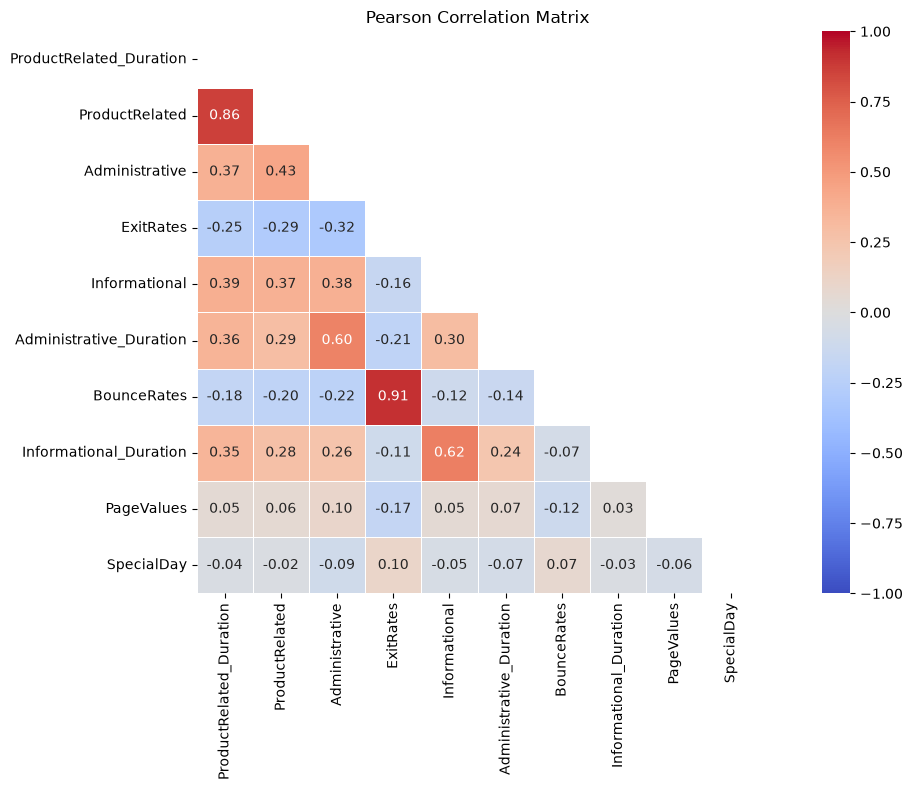


Feature correlation strength:
ProductRelated_Duration    3.850885
ProductRelated             3.812687
Administrative             3.773153
ExitRates                  3.525477
Informational              3.436815
Administrative_Duration    3.277713
BounceRates                3.052125
Informational_Duration     2.981023
PageValues                 1.712621
SpecialDay                 1.545700
dtype: float64

Strong correlations (|r| >= 0.5):


,Feature 1,Feature 2,Correlation,Absolute Correlation
2,ExitRates,BounceRates,0.913004,0.913004
0,ProductRelated_Duration,ProductRelated,0.860927,0.860927
3,Informational,Informational_Duration,0.618955,0.618955
1,Administrative,Administrative_Duration,0.601583,0.601583


In [16]:
def correlation_analysis(
    df,
    method="pearson",
    threshold=0.5,
    figsize=(13, 8)
):
    # -----------------------------
    # 1. Select numerical features
    # -----------------------------
    numeric_df = df.select_dtypes(include=np.number)

    if numeric_df.shape[1] < 2:
        print("Not enough numerical features for correlation analysis.")
        return

    # -----------------------------
    # 2. Calculate correlation
    # -----------------------------
    corr = numeric_df.corr(method=method)

    # -----------------------------
    # 3. Calculate feature importance
    #    based on total absolute correlation
    # -----------------------------
    strength = (
        corr.abs()
        .sum()
        .sort_values(ascending=False)
    )

    # Reorder rows and columns
    corr = corr.loc[strength.index, strength.index]

    # -----------------------------
    # 4. Plot heatmap
    # -----------------------------
    plt.figure(figsize=figsize)

    mask = np.triu(
        np.ones_like(corr, dtype=bool)
    )

    sns.heatmap(
        corr,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=0.5
    )

    plt.title(
        f"{method.capitalize()} Correlation Matrix"
    )

    plt.tight_layout()
    plt.show()

    # -----------------------------
    # 5. Find strong correlations
    # -----------------------------
    pairs = []

    columns = corr.columns

    for i in range(len(columns)):
        for j in range(i + 1, len(columns)):

            value = corr.iloc[i, j]

            if abs(value) >= threshold:
                pairs.append({
                    "Feature 1": columns[i],
                    "Feature 2": columns[j],
                    "Correlation": value,
                    "Absolute Correlation": abs(value)
                })

    strong_corr = pd.DataFrame(pairs)

    if not strong_corr.empty:
        strong_corr = strong_corr.sort_values(
            "Absolute Correlation",
            ascending=False
        )

    print("\nFeature correlation strength:")
    print(strength)

    print(
        f"\nStrong correlations "
        f"(|r| >= {threshold}):"
    )

    if strong_corr.empty:
        print("No strong correlations found.")
    else:
        display(strong_corr)

    return corr, strong_corr

corr_matrix, strong_corr = correlation_analysis(
    df_copy[num_cols],
    method="pearson",
    threshold=0.5
)

## Phase 4 (Advanced EDA) : Categrical EDA

In [17]:
df_copy[cat_cols].astype("str").describe()

,Weekend,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType
count,12330,12330,12330,12330,12330,12330,12330
unique,2,10,8,13,9,20,3
top,False,May,2,2,1,2,Returning_Visitor
freq,9462,3364,6601,7961,4780,3913,10551


In [18]:
for col in cat_cols:

    print(f"{col}:\n{df[col].value_counts(normalize= True).sort_values(ascending= False)}\n")

Weekend:
Weekend
False    0.767397
True     0.232603
Name: proportion, dtype: float64

Month:
Month
May     0.272830
Nov     0.243147
Mar     0.154663
Dec     0.140065
Oct     0.044526
Sep     0.036334
Aug     0.035118
Jul     0.035036
June    0.023358
Feb     0.014923
Name: proportion, dtype: float64

OperatingSystems:
OperatingSystems
2    0.535361
1    0.209651
3    0.207218
4    0.038767
8    0.006407
6    0.001541
7    0.000568
5    0.000487
Name: proportion, dtype: float64

Browser:
Browser
2     0.645661
1     0.199676
4     0.059692
5     0.037875
6     0.014112
10    0.013220
8     0.010949
3     0.008516
13    0.004947
7     0.003974
12    0.000811
11    0.000487
9     0.000081
Name: proportion, dtype: float64

Region:
Region
1    0.387672
3    0.194891
4    0.095864
2    0.092133
6    0.065288
7    0.061719
9    0.041444
8    0.035199
5    0.025791
Name: proportion, dtype: float64

TrafficType:
TrafficType
2     0.317356
1     0.198783
3     0.166423
4     0.086699
13    0.0

### (B) Cat features with target

In [19]:
for col in cat_cols:

    result = (
        df_copy.groupby(col)["target"]
        .agg(["count", "mean"])
        .sort_values("mean", ascending=False)
        .T
    )

    print("\n", col)
    display(result)


 Weekend


Weekend,True,False
count,2868.000000,9462.000000
mean,0.173989,0.148911



 Month


Month,Nov,Oct,Sep,Aug,Jul,Dec,May,June,Mar,Feb
count,2998.000000,549.000000,448.000000,433.00000,432.000000,1727.000000,3364.000000,288.000000,1907.000000,184.000000
mean,0.253502,0.209472,0.191964,0.17552,0.152778,0.125072,0.108502,0.100694,0.100682,0.016304



 OperatingSystems


...

Region,9,2,5,1,7,4,3,6,8
count,511.000000,1136.000000,318.000000,4780.000000,761.000000,1182.000000,2403.000000,805.00000,434.000000
mean,0.168297,0.165493,0.163522,0.161297,0.156373,0.148054,0.145235,0.13913,0.129032



 TrafficType


TrafficType,16,7,8,20,2,5,10,11,4,14,6,1,9,3,19,13,12,15,18,17
count,3.000000,40.0,343.000000,198.000000,3913.000000,260.000000,450.0,247.000000,1069.00000,13.000000,444.000000,2451.000000,42.000000,2052.000000,17.000000,738.000000,1.0,38.0,10.0,1.0
mean,0.333333,0.3,0.276968,0.252525,0.216458,0.215385,0.2,0.190283,0.15435,0.153846,0.119369,0.106895,0.095238,0.087719,0.058824,0.058266,0.0,0.0,0.0,0.0



 VisitorType


VisitorType,New_Visitor,Other,Returning_Visitor
count,1694.000000,85.000000,10551.000000
mean,0.249115,0.188235,0.139323


In [20]:
pd.crosstab(
    df_copy["OperatingSystems"],
    df_copy["target"],
    normalize="index"
)

target,0,1
OperatingSystems,,
1,0.853385,0.146615
2,0.825027,0.174973
3,0.895108,0.104892
4,0.822176,0.177824
5,0.833333,0.166667
6,0.894737,0.105263
7,0.857143,0.142857
8,0.784810,0.215190


## Phase 5 :Split

In [21]:
from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test = train_test_split(X , y , test_size=0.25 , random_state=42 , stratify= y)

## Phase 6: Pipeline Creation

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler , RobustScaler , OneHotEncoder , MinMaxScaler

num_pipeline = Pipeline([
    
    ("scaler_2", RobustScaler()),
    ("imputer" , SimpleImputer(strategy= "median"))
])

cat_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ("imputer" , SimpleImputer(strategy="most_frequent"))
])

In [23]:
from sklearn.compose import ColumnTransformer 

preprocessor = ColumnTransformer([
    ("num" , num_pipeline , num_cols),
    ("cat" , cat_pipeline , cat_cols)
])

## Phase 7: Applying Pipeline

In [24]:
from sklearn.linear_model import LogisticRegression 
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier 
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier 
from sklearn.svm import SVC

models = {
    "Xgboost" : XGBClassifier(),
    "Random Forest": RandomForestClassifier(),
    "Decision Tree": DecisionTreeClassifier(),
    "SVM" : SVC(),
    "KNN": KNeighborsClassifier(),
    "Logistic Regression": LogisticRegression()
}

def build_pipeline(model):
    return Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ]) 

pipelines = {
    name: build_pipeline(model)
    for name, model in models.items()
}


trained_models = {}

for name, pipeline in pipelines.items():
    trained_models[name] = pipeline.fit(x_train, y_train)



/home/amor/Projects/ETA/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Phase 8: Evaluation

In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

for name, model in trained_models.items():
    y_pred = model.predict(x_test)

    print(f"{name}:")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print(f"F1: {f1_score(y_test, y_pred)}\n")

Xgboost:
Accuracy: 0.8962049951346092
Precision: 0.7138964577656676
Recall: 0.549266247379455
F1: 0.6208530805687204

Random Forest:
Accuracy: 0.8949075575737918
Precision: 0.749185667752443
Recall: 0.48218029350104824
F1: 0.5867346938775511

Decision Tree:
Accuracy: 0.8478754459941615
Precision: 0.5080645161290323
Recall: 0.5283018867924528
F1: 0.5179856115107914

SVM:
Accuracy: 0.8806357444048005
Precision: 0.6835016835016835
Recall: 0.42557651991614254
F1: 0.524547803617571

KNN:
Accuracy: 0.8816088225754135
Precision: 0.6546961325966851
Recall: 0.4968553459119497
F1: 0.564958283671037

Logistic Regression:
Accuracy: 0.8819331819656179
Precision: 0.7383966244725738
Recall: 0.3668763102725367
F1: 0.49019607843137253



## Phase 9: Save them in joblib

In [26]:
import joblib

joblib.dump(
    trained_models,
    "trained_models.pkl"
)

['trained_models.pkl']